# Where the models fail: popularity slices, activity slices, cold items and cold-start users

In [1]:
import json, sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from recsys.config import RESULTS_DIR, COLD_REVEAL
from recsys.data import load

ORDER = ['popularity', 'knn', 'als', 'svd', 'bpr', 'ncf', 'sasrec', 'content']   # models in the order of the comparison
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, GRAY, ORANGE = "#2a6fb0", "#8a8f98", "#d9822b"
ROOT = Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

data = load()
cold = load(ROOT / "data" / "processed_coldstart")
log = data.meta["preprocess_log"]
train, val, test, users, items = data.train, data.val, data.test, data.users, data.items
allx = pd.concat([train, val, test], ignore_index=True)
allx["year"] = pd.to_datetime(allx["timestamp"], unit="ms").dt.year
print(data.meta["dataset"], "| data version", data.data_version, "| cold-start version", cold.data_version)

Amazon Reviews 2023, Video Games (McAuley Lab, UCSD) | data version 4fe78b90381a | cold-start version 6943ffc82a19


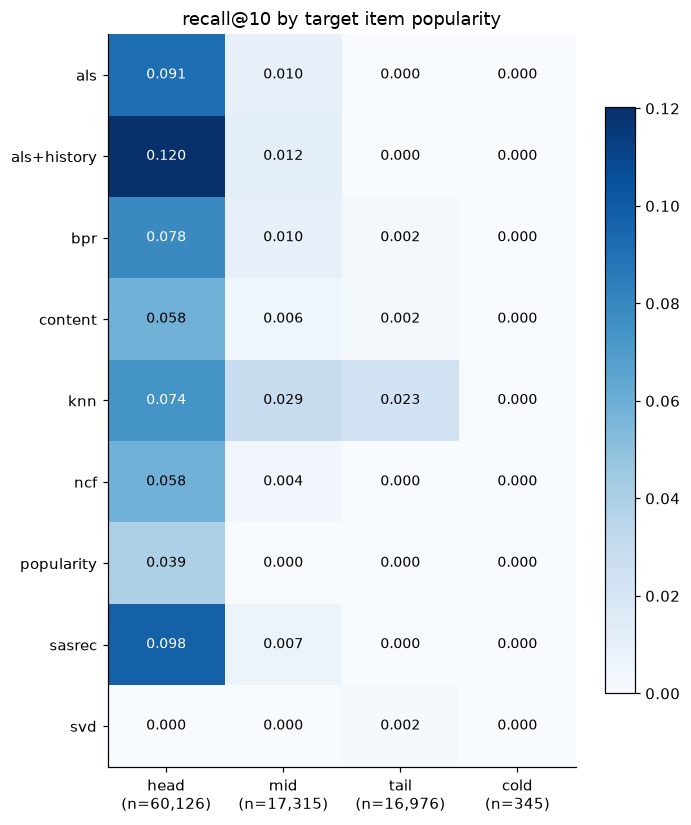

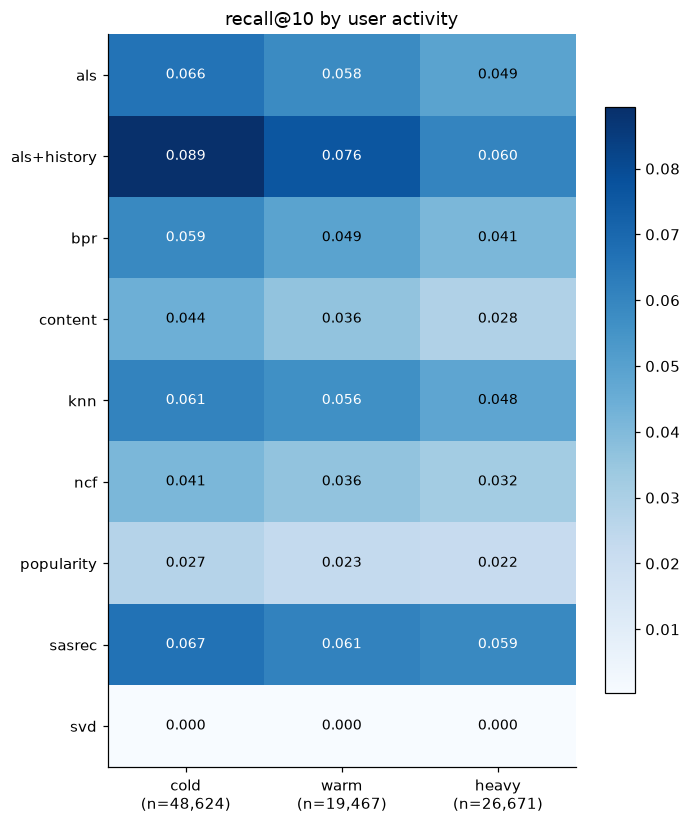

In [2]:
from recsys.plots import slice_heatmap, cold_start_curve
for kind in ("item_bin", "user_bin"):
    ax = slice_heatmap(RESULTS_DIR, kind, "recall@10"); ax.figure.savefig(FIG / f"slices_{kind}.png", dpi=150); plt.show()

63.4% of test purchases are of head items (the top 20% by training popularity), 18.3% mid, 17.9% tail and 0.4% items never seen in training. Popularity can only score on head items (Recall@10 0.0393 there, 0.0000 on mid and 0.0000 on tail items). The best model on tail items is knn (Recall@10 0.0230). Models with essentially no skill on tail items: popularity, als, als+history, ncf and sasrec. By user activity (second chart) the cold, warm and heavy thirds are shown for every model.

In [3]:
rows = []
for name in ORDER:
    p = RESULTS_DIR / f"{name}_final.json"
    if p.exists():
        c = json.loads(p.read_text())["test_slices"]["item_bin"]["cold"]
        rows.append({"model": name, "recall@10 on never-seen items": c["recall@10"], "n": c["n"]})
pd.DataFrame(rows).round(4)

,model,recall@10 on never-seen items,n
0,popularity,0.0,345
1,knn,0.0,345
2,als,0.0,345
3,svd,0.0,345
4,bpr,0.0,345
5,ncf,0.0,345
6,sasrec,0.0,345
7,content,0.0,345


The 345 test purchases of items that never appeared in training: no model has any of them in its top 10. A model that reads item text can in principle reach them. Where the held-out items actually rank (median rank, share in the top 100 and in the top 1,000): popularity: median rank 25,606 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; knn: median rank 25,606 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; sasrec: median rank 25,554 of 25,612, 0.0% in the top 100, 0.0% in the top 1,000; content: median rank 16,832 of 25,612, 0.0% in the top 100, 1.4% in the top 1,000. These items have no popularity prior and no neighbours, so they rarely outrank items with any interaction history.

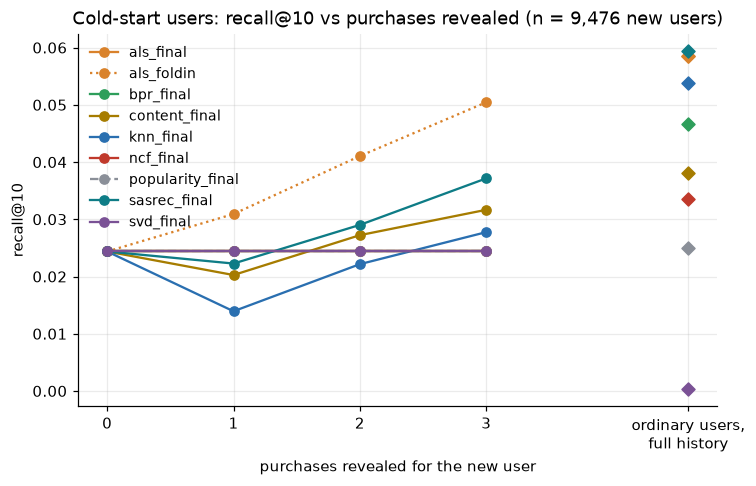

In [4]:
ax = cold_start_curve(RESULTS_DIR / "processed_coldstart"); ax.figure.savefig(FIG / "cold_start_curve.png", dpi=150); plt.show()

New users are 9,476 users held out of training entirely; the model sees only their first n purchases and must rank their last purchase. Recall@10 for n = 0, 1, 2, 3: popularity is flat at 0.0244, the floor (n = 0 means no information, so every model falls back to popularity). knn 0.0244 / 0.0139 / 0.0222 / 0.0278 (passes the floor at n = 3); als 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); svd 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); bpr 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); ncf 0.0244 / 0.0244 / 0.0244 / 0.0244 (never above the floor); sasrec 0.0244 / 0.0223 / 0.0290 / 0.0371 (passes the floor at n = 2); content 0.0244 / 0.0203 / 0.0272 / 0.0317 (passes the floor at n = 2). als, svd, bpr and ncf stay exactly on the floor because they learn a vector per user during training and have none for a new user; they cannot use the revealed purchases. Folding the revealed purchases into ALS with the item factors fixed lifts it to 0.0244 / 0.0309 / 0.0411 / 0.0504. With a single purchase, knn, sasrec and content score below the floor, so they do worse than showing best-sellers. With three purchases the best model is als with fold-in (0.0504, 2.1 times the floor). For comparison, the other 90% of users, with their full history, get Recall@10 0.0595 from sasrec on this data. Revealed purchases help only the models that can use them.